## Task 1 — Exploratory Data Analysis (EDA): Superstore Sales

### Step_1. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

### Step_2. Load and Explore the data

In [3]:
df_raw = pd.read_csv("D:\Datheon internship\superstore_sales.csv")
print("Raw shape:", df_raw.shape)

Raw shape: (10800, 21)


In [4]:
print(df_raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

In [5]:
print(df_raw.head())

  Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
1      2  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
2      3  CA-2017-138688   6/12/2017   6/16/2017    Second Class    DV-13045   
3      4  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
4      5  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff  Corporate  United States      Los Angeles  California   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region       Product ID         Category 

In [6]:
print(df_raw.isna().sum())

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [16]:
# Keep rows where Row ID is numeric:

df = df_raw[pd.to_numeric(df_raw["Row ID"], errors="coerce").notna()].copy()
df["Row ID"] = pd.to_numeric(df["Row ID"]).astype(int)

In [17]:
# Parse dates and numeric fields safely:

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")
for col in ["Sales", "Quantity", "Discount", "Profit"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [18]:
# Remove records missing essential analysis fields:

df = df.dropna(subset=["Order Date", "Sales", "Profit","Postal Code", "Category", "Region", "Segment"])

In [19]:
# Create time features:

df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

In [20]:
## Check output:  

print("Clean shape:", df.shape)
print("Remaining missing values:")
display(df.isna().sum())

Clean shape: (9983, 24)
Remaining missing values:


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Year-Month       0
Year             0
Month            0
dtype: int64

In [21]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()
profit_margin = total_profit / total_sales * 100

kpis = pd.DataFrame({
    "Metric": ["Total Sales", "Total Profit", "Orders", "Customers", "Units Sold", "Profit Margin (%)"],
    "Value": [total_sales, total_profit, total_orders, total_customers, total_quantity, profit_margin]
})
display(kpis.round(2))

,Metric,Value
0,Total Sales,2288271.49
1,Total Profit,284152.04
2,Orders,5003.00
3,Customers,793.00
4,Units Sold,37823.00
5,Profit Margin (%),12.42


In [24]:
## customer_summary

customer_summary = (df.groupby(["Customer ID", "Customer Name"])
    .agg(Sales=("Sales", "sum"), Orders=("Order ID", "nunique"), Quantity=("Quantity", "sum"))
    .sort_values("Sales", ascending=False))

display(customer_summary.head(10))

,,Sales,Orders,Quantity
Customer ID,Customer Name,,,
SM-20320,Sean Miller,25043.050,5,50.0
TC-20980,Tamara Chand,19052.218,5,42.0
RB-19360,Raymond Buch,15117.339,6,71.0
TA-21385,Tom Ashbrook,14595.620,4,36.0
AB-10105,Adrian Barton,14473.571,10,73.0
KL-16645,Ken Lonsdale,14175.229,12,113.0
SC-20095,Sanjit Chand,14142.334,9,87.0
HL-15040,Hunter Lopez,12873.298,6,50.0
SE-20110,Sanjit Engle,12209.438,11,78.0


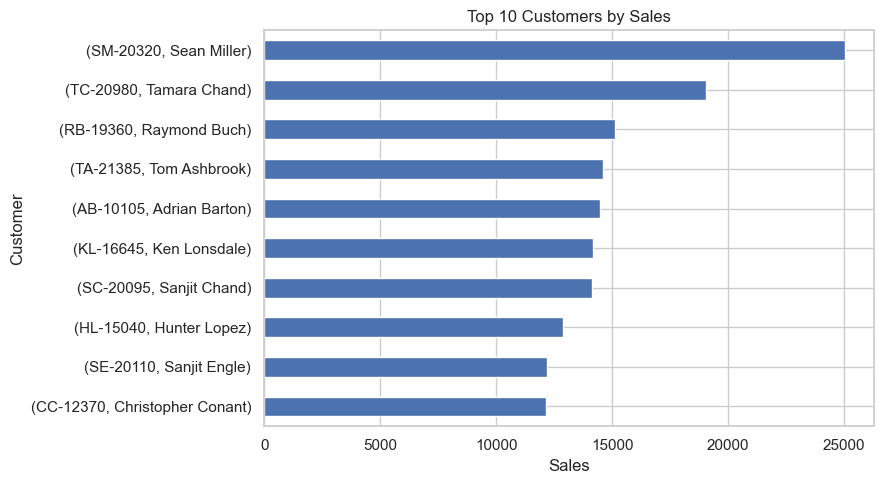

In [25]:
# Top 10 customers by sales:

customer_summary.head(10)["Sales"].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Customers by Sales")
plt.xlabel("Sales")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

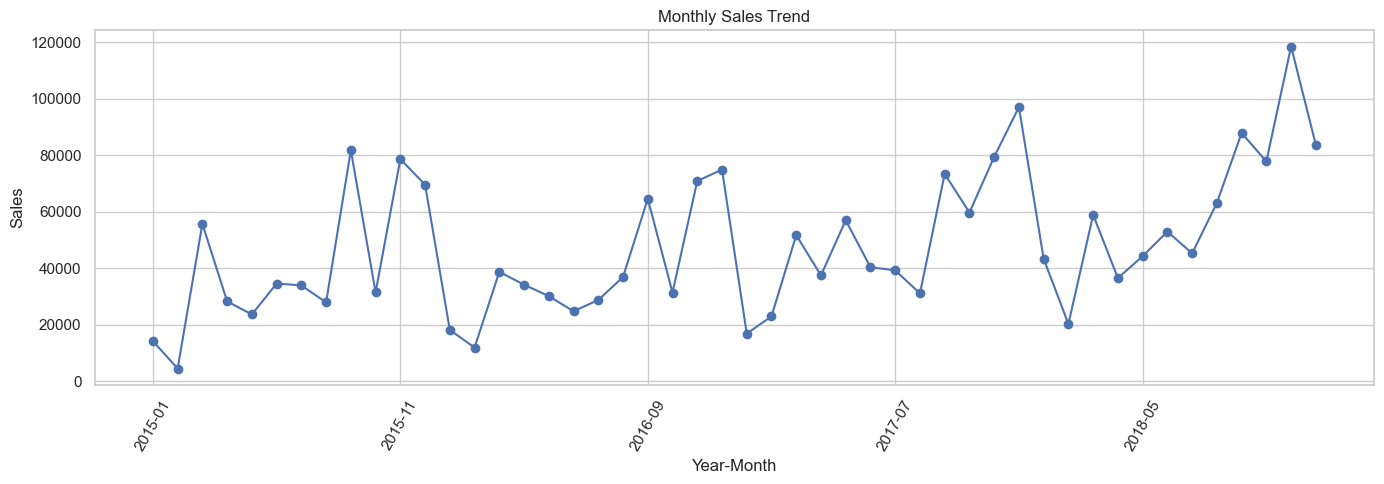

Highest-sales month: 2018-11 118447.825
Lowest-sales month: 2015-02 4519.892


In [26]:
monthly_sales = df.groupby("Year-Month")["Sales"].sum().sort_index()
plt.figure(figsize=(14, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

print("Highest-sales month:", monthly_sales.idxmax(), monthly_sales.max())
print("Lowest-sales month:", monthly_sales.idxmin(), monthly_sales.min())

,Sales,Profit,Orders
Category,,,
Technology,834554.2730,145007.6618,1541
Furniture,736879.6953,17259.3458,1762
Office Supplies,716837.5220,121885.0358,3740


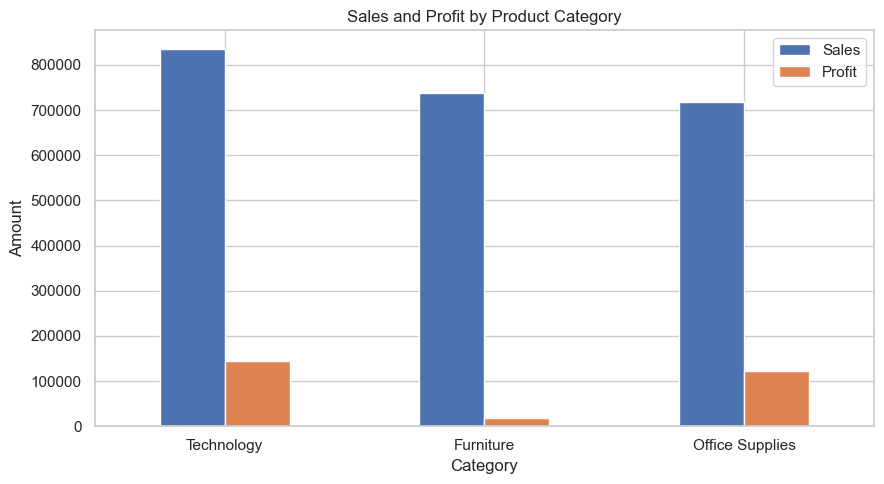

In [27]:
category_summary = (df.groupby("Category")
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
    .sort_values("Sales", ascending=False))
display(category_summary)

category_summary[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 5))
plt.title("Sales and Profit by Product Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Sales,Profit
Region,,
West,725457.8245,108418.4489
East,669851.8700,89277.8017
Central,501239.8908,39706.3625
South,391721.9050,46749.4303


,Sales,Profit,Customers,Orders
Segment,,,,
Consumer,1.160049e+06,133744.0932,409,2584
Corporate,6.998641e+05,90445.9067,236,1511
Home Office,4.283584e+05,59962.0435,148,908


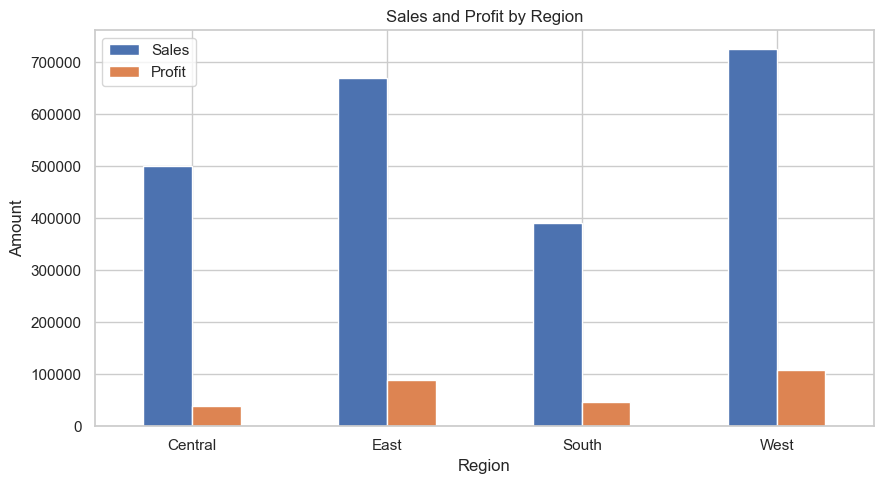

In [28]:
region_summary = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
segment_summary = df.groupby("Segment").agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Customers=("Customer ID", "nunique"), Orders=("Order ID", "nunique")
)
display(region_summary.sort_values("Sales", ascending=False))
display(segment_summary.sort_values("Sales", ascending=False))

region_summary[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 5))
plt.title("Sales and Profit by Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

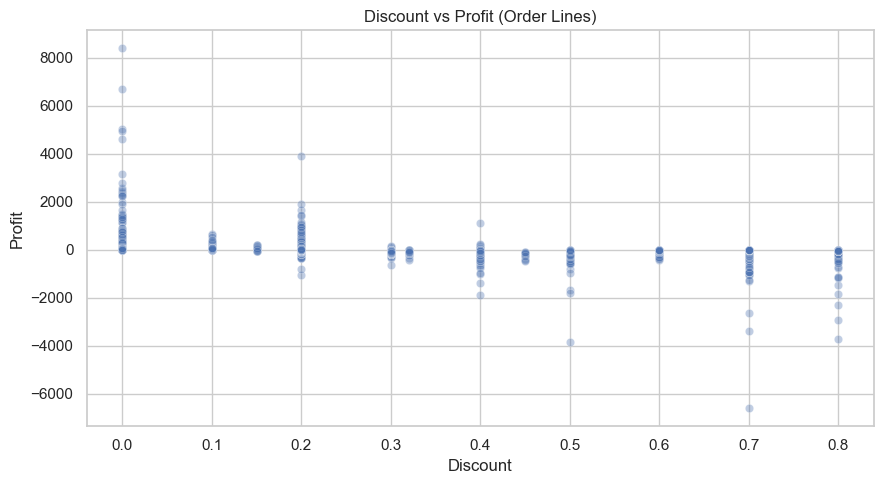

,Sales,Profit,Rows,Profit per line
Discount,,,,
0.00,1.078979e+06,318742.6249,4787,66.585048
0.10,5.436935e+04,9029.1770,94,96.055074
0.15,2.755852e+04,1418.9915,52,27.288298
0.20,7.645944e+05,90337.3060,3657,24.702572
0.30,1.032267e+05,-10369.2774,227,-45.679636
0.32,1.449346e+04,-2391.1377,27,-88.560656
0.40,1.164178e+05,-23057.0504,206,-111.927429
0.45,5.484974e+03,-2493.1111,11,-226.646464
0.50,5.891854e+04,-20506.4281,66,-310.703456


In [29]:
# Scatter plot at transaction-line level
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35)
plt.title("Discount vs Profit (Order Lines)")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

discount_summary = df.groupby("Discount").agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"), Rows=("Discount", "size")
)
discount_summary["Profit per line"] = discount_summary["Profit"] / discount_summary["Rows"]
display(discount_summary.sort_index())

In [30]:
# Values used to support the findings
display(category_summary)
display(region_summary)
display(segment_summary)
display(discount_summary)

,Sales,Profit,Orders
Category,,,
Technology,834554.2730,145007.6618,1541
Furniture,736879.6953,17259.3458,1762
Office Supplies,716837.5220,121885.0358,3740


,Sales,Profit
Region,,
Central,501239.8908,39706.3625
East,669851.8700,89277.8017
South,391721.9050,46749.4303
West,725457.8245,108418.4489


,Sales,Profit,Customers,Orders
Segment,,,,
Consumer,1.160049e+06,133744.0932,409,2584
Corporate,6.998641e+05,90445.9067,236,1511
Home Office,4.283584e+05,59962.0435,148,908


,Sales,Profit,Rows,Profit per line
Discount,,,,
0.00,1.078979e+06,318742.6249,4787,66.585048
0.10,5.436935e+04,9029.1770,94,96.055074
0.15,2.755852e+04,1418.9915,52,27.288298
0.20,7.645944e+05,90337.3060,3657,24.702572
0.30,1.032267e+05,-10369.2774,227,-45.679636
0.32,1.449346e+04,-2391.1377,27,-88.560656
0.40,1.164178e+05,-23057.0504,206,-111.927429
0.45,5.484974e+03,-2493.1111,11,-226.646464
0.50,5.891854e+04,-20506.4281,66,-310.703456
